In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

from pyprojroot import here

# Ajout de la racine au sys.path pour rendre les dossiers importables
root_dir = here()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from ann_playground.data import fetch_and_save_dataset

In [2]:
# Load Data
output_dir = Path(root_dir) / "data" / "raw_data"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "data.csv"

if not output_path.is_file():
    dataset_id = 697
    df,X,y = fetch_and_save_dataset(dataset_id, output_path)

Note : on peut télécharger le fichier à l'adresse 
https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

In [3]:
# Load Data
output_dir = Path(root_dir) / "data" / "raw_data"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "data.csv"

df = pd.read_csv(output_path, encoding='ascii')

In [4]:
df.head(5)

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
# Transforme l'index en une colonne classique nommée "id"
# df = df.reset_index().rename(columns={"index": "id"})

In [5]:
df.shape

(4424, 37)

<hr style="width: 50%; margin: 12px auto 0px auto;" />

# 1. Encodage, Doublons, colonnes vides

In [6]:
import numpy as np
import pandas as pd
# from eda_utils import *

### 1a. Encodage
On vérifie l'encodage au tout début d'une EDA pour éviter de charger de la donnée corrompue sans s'en rendre compte.
- Si on essaie de lire un fichier encodé en latin-1 ou cp1252 en lui imposant du utf-8, Python plante immédiatement lors du pd.read_csv().
- Parfois, le fichier s'ouvre sans erreur, mais les caractères sont mal interprétés : Montréal devient MontrÃ©al

In [7]:
import unicodedata
import chardet

with open(output_path, 'rb') as file :
    encodage = chardet.detect(file.read(10000))

print(encodage)

{'encoding': 'ascii', 'confidence': 1.0, 'language': 'en', 'mime_type': 'text/plain'}


### 

### 1b. Analyse des doublons

In [8]:
cols_sans_id = [col for col in df.columns if col != 'id']
nb_doublons = df.duplicated(subset=cols_sans_id).sum()

if nb_doublons == 0:
    print("Aucun doublon trouvé dans le DataFrame.")
else :
    print(f"Nombre de doublons trouvés : {nb_doublons}\nAppelez la fonction duplicate_rows()")

Aucun doublon trouvé dans le DataFrame.


In [ ]:
# Nombre total de lignes en double
# df.duplicated().sum()

# Afficher toutes les lignes impliquées dans un doublon
# df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

# Doublons basés sur une ou plusieurs colonnes
# df[df.duplicated(subset=['id_client'], keep=False)]

# Garder la première occurrence et supprimer les autres
# df_clean = df.drop_duplicates()

# Ou modifier directement le DataFrame existant
# df.drop_duplicates(inplace=True)

### 1c. Colonnes vides

In [9]:
# Remplacer les espaces blancs ou chaînes "null" / "None" par np.nan
df_clean = df.replace(r'^\s*$', np.nan, regex=True).replace(['null', 'None', 'nan', 'N/A'], np.nan)

# Tableau récapitulatif des valeurs manquantes
na_summary = pd.DataFrame({
    'Manquants (count)': df_clean.isna().sum(),
    'Manquants (%)': (df_clean.isna().mean() * 100).round(2)
})

na_summary_filtered = na_summary[na_summary['Manquants (count)'] > 0]
if not na_summary_filtered.empty:
    print("Colonnes avec valeurs manquantes :")
    na_summary[na_summary['Manquants (count)'] > 0].sort_values(by='Manquants (%)', ascending=False)
else:
    print("Aucun colonne vide.")


Aucun colonne vide.


In [10]:
# Colonnes dont toutes les valeurs sont NaN"""
empty_columns = df.columns[df.isna().all()].tolist()

empty_columns

[]

In [11]:
df = df.dropna(axis=1, how='all')

In [12]:
# Colonnes contenant des valeurs manquantes explicites : NaN, None, '', 'na', 'null'
missing_vals = {np.nan, None, '', 'na', 'NA', 'null', 'NULL'}
cols = []
for col in df.columns:
    if df[col].isin(missing_vals).any():
        cols.append(col)
cols

[]

### 1d. Contrôle et harmonisation des types de données

In [13]:
df.info()
# df.dtypes ou df.info(), puis conversion avec pd.to_datetime(), pd.to_numeric(), ou .astype('category').

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

<hr style="width: 50%; margin: 12px auto 0px auto;" />

# 2. Statistiques descriptives
Les statistiques descriptives dans une EDA permettent de résumer la forme, le centre et la dispersion de tes données pour repérer immédiatement les anomalies, les asymétries ou les valeurs aberrantes.

In [14]:
df.describe(include='all')

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graduate
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2209
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969,NaN
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935,NaN
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000,NaN
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000,NaN
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000,NaN
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000,NaN


1. Mesures de tendance centrale (Où se situe le milieu ?)  
    - Moyenne vs Médiane : La différence entre les deux t'indique la présence d'outliers.  
        Exemple : Si le salaire moyen est de $4\,500\text{ €}$ mais la médiane est à $2\,100\text{ €}$, cela signifie que quelques très hauts salaires tirent la moyenne vers le haut.
    - Mode : La valeur la plus fréquente (très utile pour les variables catégorielles ou discrètes).

2. Mesures de dispersion (Comment les données s'étalent-elles ?)  
    - Écart-type (Standard Deviation) & Variance : Mesurent la distance moyenne des points par rapport à la moyenne.
    - Min et Max : Permettent de vérifier les limites physiques/métier (ex. un âge min de $-5$ ou max de $300$ indique une erreur de saisie).
    - Quartiles ($Q1$, $Q2$/Médiane, $Q3$) & Ecart Interquartile ($IQR = Q3 - Q1$) : L'$IQR$ donne la plage où se trouvent les $50\%$ centraux des données (très robuste aux outliers).

3. Mesures de forme de la distribution  
    - Asymétrie (Skewness) :  
    $>0$ : étalée vers la droite (beaucoup de petites valeurs, quelques très grandes).  
    $<0$ : étalée vers la gauche.
    - Aplatissement (Kurtosis) : Indique si les valeurs sont très concentrées autour de la moyenne ou si les "queues" de distribution sont épaisses (présence fréquente d'outliers).

### 2a. variables numériques et variables catégorielles

La distinction entre numériques et catégorielles est un point clé : il y a énormément de variables catégorielles qui sont encodées sous forme de nombres entiers (par exemple, le mode d'application, le statut marital, les qualifications des parents, etc.). Si on ne les redéfinit pas proprement, Pandas les traite toutes comme du numérique.

In [15]:
df.columns

Index(['Marital Status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd s

In [16]:
# Identifier le nombre de valeurs uniques 
df.nunique().sort_values()

# df['colonne'].value_counts()
# df['colonne'].str.strip().str.lower()

Daytime/evening attendance                          2
Displaced                                           2
Debtor                                              2
Educational special needs                           2
International                                       2
Scholarship holder                                  2
Gender                                              2
Tuition fees up to date                             2
Target                                              3
Marital Status                                      6
Application order                                   8
Inflation rate                                      9
Curricular units 2nd sem (without evaluations)     10
Unemployment rate                                  10
GDP                                                10
Curricular units 1st sem (without evaluations)     11
Course                                             17
Previous qualification                             17
Application mode            

- Les binaires et catégorielles déguisées en entiers (ex: Marital Status, Gender, Debtor, Course, etc., de 2 à ~46 valeurs max).

- Les vraies continues / notes / scores (ex: Admission grade, notes des semestres, avec des centaines de valeurs uniques).

- Les macro-économiques (Inflation rate, Unemployment rate, GDP, qui ont une faible cardinalité mais sont bien continues).

### 2b. Histogrammes : Variables continues
Pour les vraies variables continues (Admission grade, notes des semestres, PIB, etc.), ils ont un grand intérêt. Ces histogrammes permettent de repérer :
- Des valeurs aberrantes (ex: une note à 200 au lieu de 20).
- L'asymétrie (skewness) des distributions, ce qui t'aide à comprendre si certaines données nécessitent une transformation (comme un log) avant d'être passées dans le modèle.
- L'échelle globale des valeurs.

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, Tuple, Optional, Any, List, Iterable
import math

def plot_numeric_histograms(
    X: pd.DataFrame,
    bins: int = 40,
    n_cols: int = 3,
    figsize_per_col: Tuple[int, int] = (5, 3),
) -> None:
    """
    Affiche les histogrammes de toutes les colonnes numériques.

    Parameters
    ----------
    X : pd.DataFrame
        Données d'entrée.
    bins : int
        Nombre de bins pour les histogrammes.
    n_cols : int
        Nombre de graphes par ligne.
    figsize_per_col : tuple
        Taille d'un subplot (largeur, hauteur).
    """
    num_cols = X.select_dtypes(include=["number"]).columns
    n_plots = len(num_cols)
    if n_plots == 0:
        return
    n_rows = math.ceil(n_plots / n_cols)
    plt.figure(figsize=(n_cols * figsize_per_col[0], n_rows * figsize_per_col[1]))
    for i, col in enumerate(num_cols, 1):
        plt.subplot(n_rows, n_cols, i)
        sns.histplot(X[col].dropna(), bins=bins)
        plt.xlabel("")   # masque axe X
        plt.ylabel("")   # masque axe Y
        plt.grid(True, alpha=0.3)
        plt.title(col)
    plt.tight_layout()
    plt.show()

In [18]:
feature_names = [
    'Previous qualification (grade)',
    'Admission grade',
    'Curricular units 2nd sem (grade)',
    'Curricular units 1st sem (grade)',
    'Inflation rate',
    'Unemployment rate',
    'GDP'
]

# Train DataFrame
df_numerique = pd.DataFrame(df, columns=feature_names)

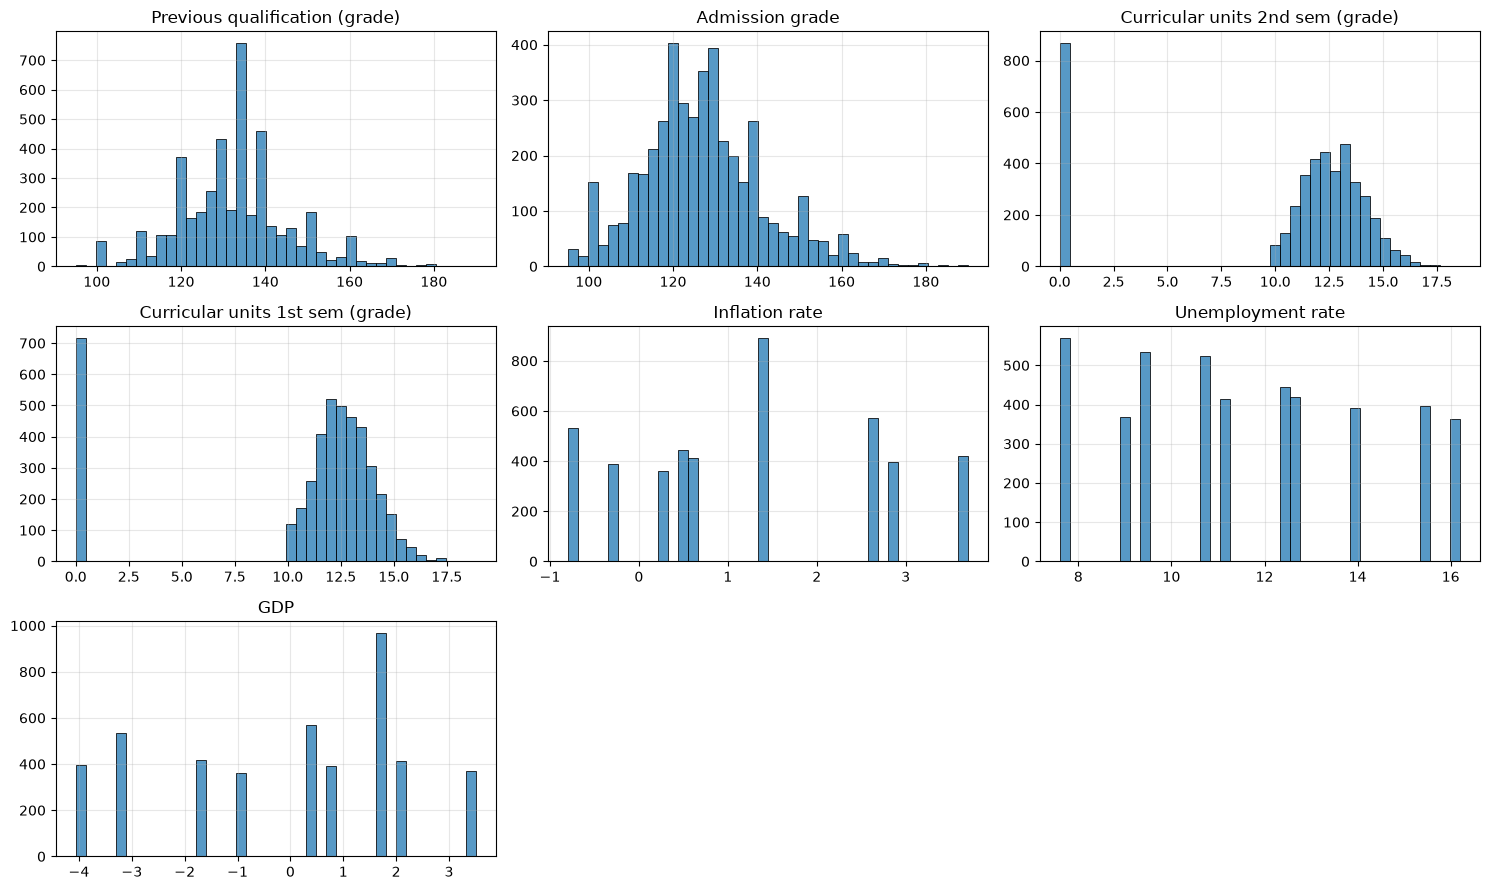

In [19]:
plot_numeric_histograms(df_numerique, bins=40, n_cols=3)

- Previous qualification et Admission grade ont des distributions globalement gaussiennes (avec une légère asymétrie à droite).

- Inflation rate, Unemployment rate, GDP) se comportent comme des variables discrètes ou catégorisées dans ce dataset (avec des valeurs fixes en fonction de la période d'inscription) : ce ne sont pas des lois continues classiques, mais cela reste tout à fait gérable pour un StandardScaler.

- Les notes des semestres 1 et 2 ont un pic massif à 0, qui représente probablement les étudiants qui n'ont pas eu d'évaluation ou qui ont abandonné.

a. Pour un MLP, on ne peut laisser ces 0 bruts sans distinction, ce qui fausserait complètement le scaling.

In [20]:
# Pour le 1er semestre
df['Sem1_grade_missing'] = (df['Curricular units 1st sem (grade)'] == 0).astype(int)

# Pour le 2ème semestre
df['Sem2_grade_missing'] = (df['Curricular units 2nd sem (grade)'] == 0).astype(int)

- On remplace le 0 par un NaN

In [21]:
df['Curricular units 1st sem (grade)'] = df['Curricular units 1st sem (grade)'].replace(0, float('nan'))
df['Curricular units 2nd sem (grade)'] = df['Curricular units 2nd sem (grade)'].replace(0, float('nan'))

b. Pour gérer proprement ces NaN créés artificiellement sans perturber ton modèle, la bonne pratique avec scikit-learn est d'utiliser un Pipeline ou d'enchaîner deux briques indispensables : un SimpleImputer (pour remplacer les NaN par une valeur de référence comme la médiane) et un StandardScaler (pour normaliser les données).

In [22]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# 1. Définition de tes colonnes continues (avec les notes nettoyées contenant des NaN)
continuous_cols = [
    'Previous qualification (grade)', 
    'Admission grade', 
    'Curricular units 1st sem (grade)', 
    'Curricular units 2nd sem (grade)', 
    'Inflation rate', 
    'Unemployment rate', 
    'GDP'
]

# 2. Création d'un sous-pipeline pour les variables continues : 
# On impute les NaN par la médiane, puis on applique le StandardScaler
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 3. Application via un ColumnTransformer pour ne traiter que les colonnes continues
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, continuous_cols)
    ],
    remainder='passthrough' # Garde les autres colonnes (catégorielles et indicateurs _missing) intactes
)

### 2c. Variables catégorielles : One-Hot Encoding
L'objectif est d'éviter que le réseau de neurones (le MLP) ne suppose un ordre ou une distance mathématique entre les catégories (par exemple, que la catégorie 4 soit "plus grande" que la catégorie 2, ce qui n'a aucun sens pour le statut marital ou le genre).

Le One-Hot Encoding transforme chaque variable catégorisée en plusieurs colonnes binaires (0 ou 1).

In [23]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Liste de tes variables catégorielles (le reste de ton dataset)
categorical_cols = [
    'Marital Status', 'Application mode', 'Application order', 'Course',
    'Daytime/evening attendance', 'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification", "Mother's occupation",
    "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment',
    'International'
]

# 2. Configuration du transformateur pour les catégorielles
# handle_unknown='ignore' évite les erreurs si de nouvelles catégories apparaissent dans le jeu de test
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# 3. Intégration complète dans le ColumnTransformer (Continu + Catégoriel + Indicateurs de notes manquantes)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, continuous_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='passthrough' # Laisse intacts les indicateurs _missing créés plus tôt
)

<hr style="width: 50%; margin: 12px auto 0px auto;" />

# 3. Corrélation

### 3a. On regarde la matrice de corrélation des variables continues avant de toucher au train/test split ou au reste du pipeline.

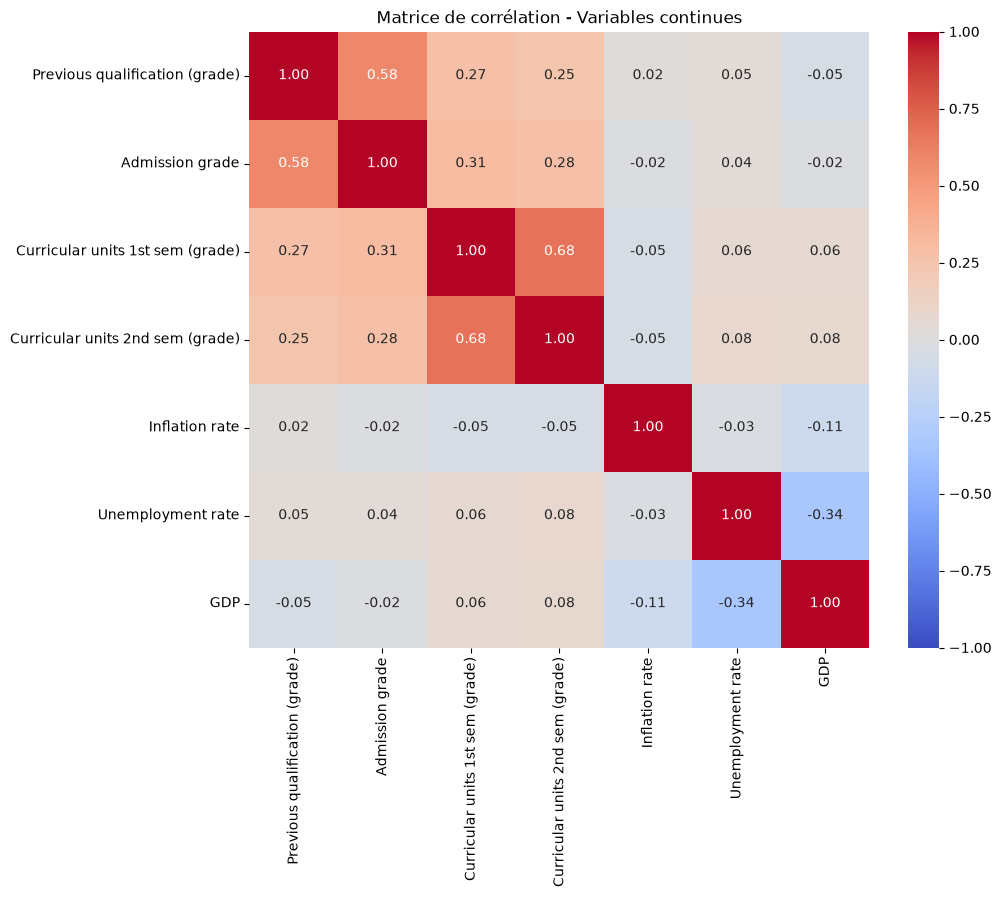

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Tes variables continues (incluant les notes nettoyées)
continuous_cols = [
    'Previous qualification (grade)', 
    'Admission grade', 
    'Curricular units 1st sem (grade)', 
    'Curricular units 2nd sem (grade)', 
    'Inflation rate', 
    'Unemployment rate', 
    'GDP'
]

# Affichage de la matrice de corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(df[continuous_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title("Matrice de corrélation - Variables continues")
plt.show()

Cette matrice de corrélation apporte des enseignements très clairs et rassurants pour la suite :
- La cohérence académique :
    - On observe une forte corrélation (0.68) entre les notes du 1er semestre et celles du 2ème semestre. C'est tout à fait logique : un étudiant qui performe au premier semestre a tendance à faire de même au second.
    - La note de qualification précédente et la note d'admission sont également bien corrélées (0.58), ce qui valide la continuité du parcours scolaire de l'étudiant.   
- L'indépendance des facteurs macro-économiques :
    - Les variables comme l'inflation, le chômage et le PIB affichent des corrélations quasi nulles avec les notes des étudiants (proches de 0). C'est une excellente nouvelle pour un MLP : ces variables macro-économiques apportent une information complémentaire et non redondante par rapport aux notes scolaires.
    - On note juste une corrélation négative classique entre le chômage et le PIB (-0.34), ce qui reflète des réalités économiques habituelles mais ne pose aucun problème de colinéarité excessive.
    
Aucune corrélation n'atteint des sommets aberrants (pas de $0.95$ ou $0.99$), ce qui signifie qu'on n'a pas besoin de supprimer de variables à cause d'une multicolinéarité destructive pour le réseau de neurones.

### 3b. Corrélation des variables catégorielles avec la cible

Pour mesurer l'association entre variables catégorielles et une cible catégorielle, on utilise principalement deux approches complémentaires :

##### → Le test statistique du $\chi^2$ (Chi-deux d'indépendance)
- Le test du Chi-deux compare la distribution observée des catégories à ce qu'on obtiendrait si la variable n'avait aucun lien avec la cible.
    - P-value $< 0.05$ : La variable a une relation statistiquement significative avec le statut de l'étudiant.
    - V de Cramér : Donne l'intensité de cette relation (entre 0 = aucun lien, et 1 = lien parfait).

In [25]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

categorical_cols = [
    'Marital Status', 'Application mode', 'Application order', 'Course',
    'Daytime/evening attendance', 'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification", "Mother's occupation",
    "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment',
    'International', 'Sem1_grade_missing', 'Sem2_grade_missing'
]

results = []

for col in categorical_cols:
    # Table de contingence entre la variable et la cible
    contingency_table = pd.crosstab(df[col], df['Target'])
    
    # Test du Chi-deux
    chi2, p_val, dof, _ = chi2_contingency(contingency_table)
    
    # Calcul du V de Cramér
    n = contingency_table.sum().sum()
    r, k = contingency_table.shape
    cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
    
    results.append({
        'Variable': col,
        'Chi2': round(chi2, 2),
        'p-value': p_val,
        'Cramers_V': round(cramers_v, 3)
    })

# Dataframe de résultats trié par force d'association
cramer_df = pd.DataFrame(results).sort_values(by='Cramers_V', ascending=False)
print(cramer_df.to_string(index=False))

                  Variable    Chi2       p-value  Cramers_V
        Sem2_grade_missing 1324.35 2.642840e-288      0.547
        Sem1_grade_missing  891.06 3.221466e-194      0.449
   Tuition fees up to date  823.55 1.471628e-179      0.431
        Scholarship holder  409.94  9.593930e-90      0.304
                    Course  558.28  2.316571e-97      0.251
         Age at enrollment  547.27  1.119506e-66      0.249
                    Debtor  259.33  4.858552e-57      0.242
                    Gender  233.27  2.222480e-51      0.230
          Application mode  466.51  1.964657e-77      0.230
       Mother's occupation  291.92  1.630859e-31      0.182
       Father's occupation  264.50  4.515439e-19      0.173
    Father's qualification  225.00  3.175007e-19      0.159
    Previous qualification  219.68  7.160305e-30      0.158
    Mother's qualification  217.95  5.823844e-21      0.157
                 Displaced   57.75  2.876311e-13      0.114
         Application order   69.61  2.27

- Les nouvelles variables sont les plus prédictives : 

    - Sem2_grade_missing ($V = 0.547$) et Sem1_grade_missing ($V = 0.449$) arrivent en tête de tout le dataset. Avoir identifié et isolé ce pic à 0 a créé les deux indicateurs catégoriels les plus puissants pour prédire le statut de l'étudiant.

    - Les variables financières et de profil sont très fortes : Tuition fees up to date ($0.431$), Scholarship holder ($0.304$), Course ($0.251$), Age at enrollment ($0.249$) et Debtor ($0.242$) apportent une information très lourde.

    - Les variables à faible signal : En bas du tableau, Nacionality ($p = 0.242$), International ($p = 0.527$) et Educational special needs ($p = 0.725$) ont une $p$-value $> 0.05$. Elles n'ont pas de lien statistiquement significatif avec la variable cible.

- Décision sur les variables non significatives :

    - Dans un premier temps, garde tout. Un réseau de neurones (MLP) est capable de mettre des poids proches de zéro sur les variables inutiles lors du passage de la rétropropagation.

    - Plus tard, si tu cherches à alléger le modèle ou réduire l'overfitting, tu pourras envisager de supprimer International, Educational special needs et Nacionality.

##### → La visualisation par empilement (Proportions par classe)
- Pour les variables catégorielles avec un fort V de Cramér, le plus parlant visuellement est d'afficher la proportion de Dropout, Enrolled et Graduate pour chaque modalité.

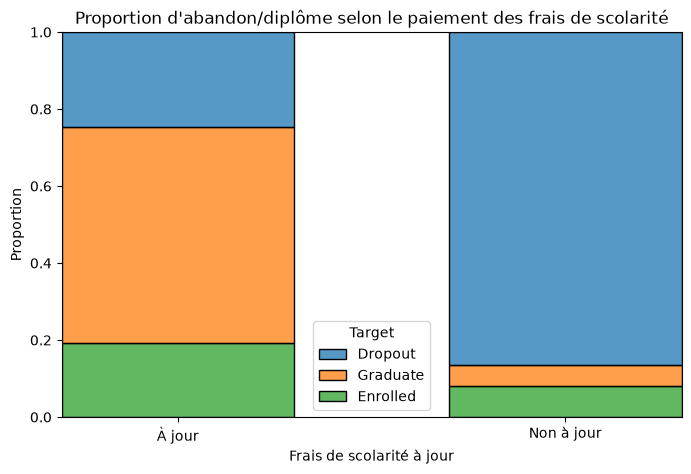

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Option 1 : Transformer en texte pour l'affichage
df_temp = df.copy()
df_temp['Tuition fees status'] = df_temp['Tuition fees up to date'].map({0: 'Non à jour', 1: 'À jour'})

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_temp, 
    x='Tuition fees status', 
    hue='Target', 
    multiple='fill', 
    stat='probability',
    shrink=0.6
)
plt.title("Proportion d'abandon/diplôme selon le paiement des frais de scolarité")
plt.ylabel("Proportion")
plt.xlabel("Frais de scolarité à jour")
plt.show()

- Ce graphique met en lumière un indicateur d'une puissance redoutable pour ton modèle :
 
    - Pour les étudiants « À jour » dans leurs frais (colonne de gauche) : La grande majorité obtient son diplôme (Graduate en orange) ou reste activement inscrite (Enrolled en vert), tandis que l'abandon y est minoritaire.   
    
    - Pour les étudiants « Non à jour » (colonne de droite) : C'est un basculement total. La quasi-totalité de la barre est bleue, ce qui montre qu'un défaut de paiement des frais de scolarité est presque systématiquement associé à un abandon (Dropout).   
    
- C'est exactement pour cela que cette variable affichait un V de Cramér aussi élevé (0.431) : pour un réseau de neurones (MLP), c'est une balise d'une clarté absolue qui va grandement l'aider à tracer ses frontières de décision.

<hr style="width: 50%; margin: 12px auto 0px auto;" />

# 4. Préparation et Sauvegarde des données

In [27]:
from typing import Union

def plot_qualitative(
    X: Union[pd.DataFrame, pd.Series], # Accepte les deux types
    top_n: int = 20,
    n_cols: int = 2,
    figsize_per_col: Tuple[int, int] = (6, 4),
    figsize: Optional[Tuple[int, int]] = None,
    height_per_row: int = 4,
) -> None:
    
    # Conversion si c'est une Series
    if isinstance(X, pd.Series):
        # On donne un nom par défaut si la série n'en a pas
        name = X.name if X.name else "Target"
        X = X.to_frame(name=name)

    """
    Affiche des barplots pour les colonnes qualitatives.

    Parameters
    ----------
    X : pd.DataFrame ou pd.series
        Données d'entrée.
    top_n : int
        Nombre de modalités affichées par colonne.
    n_cols : int
        Nombre de graphes par ligne.
    figsize_per_col : tuple
        Taille d'un subplot (largeur, hauteur).
    """
    cat_cols = X.select_dtypes(include=["object", "category", "string", "bool"]).columns
    n_plots = len(cat_cols)
    if n_plots == 0:
        return

    n_rows = math.ceil(n_plots / n_cols)
    if figsize is None:
        figsize = (n_cols * figsize_per_col[0], n_rows * height_per_row)

    plt.figure(figsize=figsize)
    

    for i, col in enumerate(cat_cols, 1):
        plt.subplot(n_rows, n_cols, i)
        vc = X[col].astype("string").value_counts(dropna=False).head(top_n)
        sns.barplot(x=vc.values, y=vc.index, color="#439cc8")
        plt.xlabel("")
        plt.ylabel("")
        plt.title(col)
        plt.grid(True, axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

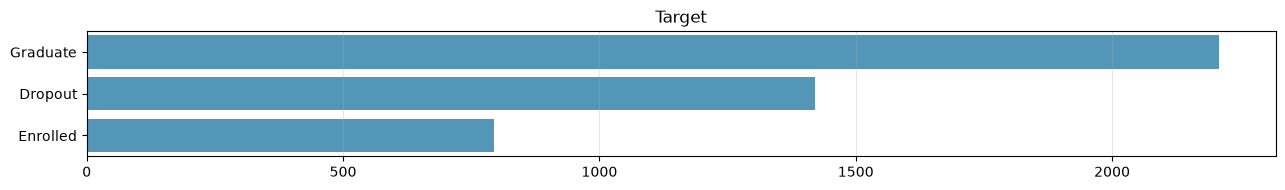

Pourcentage de Graduate : 49.93%
Pourcentage de Dropout : 32.12%
Pourcentage de Enrolled : 17.95%


In [28]:
plot_qualitative(df["Target"].astype("category"), n_cols=2, figsize=(25, 2))

# Pourcentage de "1" sur l'ensemble des observations
for valeur in ("Graduate","Dropout","Enrolled"):
    pourcentage_1 = (df["Target"].eq(valeur).mean()) * 100
    print(f"Pourcentage de {valeur} : {pourcentage_1:.2f}%")

### 4a. Encodage de la Target en int

On transforme les textes (Dropout, Enrolled, Graduate) en entiers (0, 1, 2) pour que le split et les algorithmes puissent les manipuler :

In [29]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df['Target'])

# On isole les features (X) en retirant la cible d'origine
X = df.drop(columns=['Target']).reset_index(drop=True)

### 1b. Train / Test Split (avec stratification)

Maintenant que y est prêt, on coupe les données en s'assurant de conserver les mêmes proportions de classes dans le train et le test :

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 1c. Application du ColumnTransformer sur les Features (X)

Si on fait le fit sur l'ensemble des données (train + test confondus) :
- Les statistiques calculées (moyennes, médianes, écarts-types) intègrent des informations provenant du jeu de test (X_test).
- Par conséquent, le jeu d'entraînement (X_train) va indirectement "connaître" la distribution du jeu de test. C'est de là vient la fuite (leakage) : le futur se retrouve caché dans le passé.

    - fit_transform uniquement sur X_train : Le préprocesseur apprend les statistiques en analysant X_train, et il les applique immédiatement pour transformer X_train.
    - transform (uniquement) sur X_test : utilise uniquement les statistiques qui sont déjà enregistrées en mémoire (celles apprises lors du fit sur le train) pour les appliquer à X_test.

Note : Cette mémoire se trouve dans la mémoire vive (la RAM), stockée directement à l'intérieur de l'objet Python du transformateur (le StandardScaler ou le SimpleImputer). Quand on appelle .fit(X_train), le transformateur calcule les statistiques et les enregistre sous forme d'attributs (des variables internes) rattachés à cet objet.
- scaler.mean_ : un tableau NumPy qui contient la moyenne de chaque colonne calculée sur le train.
- scaler.scale_ : un tableau NumPy qui contient l'écart-type de chaque colonne.

C'est uniquement grâce à ces tableaux stockés en interne que, lorsque tu appelles ensuite .transform(X_test), le transformateur sait quoi soustraire et diviser.

In [31]:
# .fit_transform() uniquement sur le train
X_train_prep = preprocessor.fit_transform(X_train)

# .transform() uniquement sur le test
X_test_prep = preprocessor.transform(X_test)

### 1d. Sauvegarde

On utilise le format .pkl (via la bibliothèque joblib) parce qu'ils ne sont plus de simples DataFrames pandas, mais des tableaux NumPy (ou matrices) issus du ColumnTransformer.
Le format Pickle/Joblib est idéal dans ce cas :

- Préservation de la structure : Un tableau NumPy ou une matrice transformée possède des dimensions (shape) et des types de données spécifiques. Le format .pkl sérialise l'objet Python « tel quel » en mémoire binaire, ce qui garantit qu'en le rechargeant, tu retrouves exactement le même objet, sans perte d'information ni conversion tordue.

- Incompatibilité de formats tabulaires purs : Des formats comme CSV ou Parquet sont parfaits pour des DataFrames tabulaires avec des noms de colonnes explicites. Mais une fois que le ColumnTransformer est passé par là, tes données sont souvent transformées en un gros tableau NumPy brut (où les noms de colonnes d'origine disparaissent au profit d'indices de colonnes).

- Optimisation avec joblib : Pour les tableaux NumPy contenant beaucoup de données numériques, joblib est plus performant et plus rapide que le pickle standard de Python, car il gère très efficacement le stockage sur disque des grands blocs de mémoire.

In [32]:
from pathlib import Path
from pyprojroot import here
import joblib

# 1. Création du dossier data/clean_data s'il n'existe pas
clean_data_dir = here("data/clean_data")
clean_data_dir.mkdir(parents=True, exist_ok=True)

# 2. Sauvegarde du DataFrame complet (au format parquet, idéal pour les perfs et la compression)
df.to_parquet(clean_data_dir / "df.parquet", index=False)

# 3. Sauvegarde des matrices transformées et des cibles avec joblib
joblib.dump(X_train_prep, clean_data_dir / "X_train_prep.pkl")
joblib.dump(X_test_prep, clean_data_dir / "X_test_prep.pkl")
joblib.dump(y_train, clean_data_dir / "y_train.pkl")
joblib.dump(y_test, clean_data_dir / "y_test.pkl")

print(f"✅ Tous les fichiers ont été sauvegardés avec succès dans : {clean_data_dir}")

✅ Tous les fichiers ont été sauvegardés avec succès dans : /home/philippe/work-plateforme/05-ann-playground/data/clean_data
